<a href="https://colab.research.google.com/github/Kaini9/Certification-task/blob/main/NoteBook/Certification_Task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Certification task done by :Saval Kaini**

 libaries haru sab import garum pahila

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Aba Dataset import garum


In [2]:
df = pd.read_csv("/content/NetFlix.csv")

**STEP 1: Data Collection and Exploration**

Data herum haita top 3

In [5]:
df.head(3)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,14-Aug-20,2020,TV-MA,4,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s10,Movie,1920,Vikram Bhatt,"Rajneesh Duggal, Adah Sharma, Indraneil Sengup...",India,15-Dec-17,2008,TV-MA,143,"Horror Movies, International Movies, Thrillers",An architect and his wife move into a castle t...
2,s100,Movie,3 Heroines,Iman Brotoseno,"Reza Rahadian, Bunga Citra Lestari, Tara Basro...",Indonesia,5-Jan-19,2016,TV-PG,124,"Dramas, International Movies, Sports Movies",Three Indonesian women break records by becomi...


 check garum

1.   data,  data types,  categorical columns, data shape & missing values




In [9]:
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   int64 
 10  genres        7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(2), object(10)
memory usage: 730.2+ KB


,release_year,duration
count,7787.000000,7787.000000
mean,2013.932580,69.122769
std,8.757395,50.950743
min,1925.000000,1.000000
25%,2013.000000,2.000000
50%,2017.000000,88.000000
75%,2018.000000,106.000000
max,2021.000000,312.000000


So missing values haru xa kun column ma kati xa lets see

In [10]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2389
cast,718
country,507
date_added,10
release_year,0
rating,7
duration,0


Duplicate values ni check garum haita

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.nunique()

,0
show_id,7787
type,2
title,7787
director,4049
cast,6831
country,681
date_added,1565
release_year,73
rating,14
duration,206


**STEP 2: Data Cleaning and Transformation**

So copy garera kaam garum orginal dataset ko paxi compare garna kaam lagna sakxa


In [13]:
df_clean = df.copy()

SO yo missing values haru handle garum pahila
director	2389
cast	718
country	507


so yetro dherai data drop garda data loss huna sakxa so fill gardim


In [14]:
df_clean['director'] = df_clean['director'].fillna('Not given')

df_clean['cast'] = df_clean['cast'].fillna('Not given')

df_clean['country'] = df_clean['country'].fillna('Not given')

yo columns ko lagi chai date_added	10
rating	7

thorai data xa just total ma 17 so drop gardim

In [15]:
df_clean = df_clean.dropna(subset=["rating"])
df_clean = df_clean.dropna(subset=["date_added"])

lets check missing values now and compare

In [17]:
df.info()
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   int64 
 10  genres        7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(2), object(10)
memory usage: 730.2+ KB
<class 'pandas.core.frame.DataFrame'>
Index: 7770 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7770 non-null   object
 1   type          7770 

In [18]:
df_clean.duplicated().sum()

np.int64(0)

So missing values and duplicate values haru are handled

date added ko data type pani milaidim haita aba

In [ ]:
df_clean['date_added'] = df_clean['date_added'].str.strip()

df_clean['date_added'] = pd.to_datetime(
    df_clean['date_added'],
    format='mixed',
)

In [21]:
df_clean['date_added'].dtype

dtype('<M8[ns]')

DURATION COLUMN MA 120= 120 MINUTES BUT IN TV SHOWS 3=3 SEASONS THATS DIFFERENT

In [25]:
df_clean['movie_duration'] = np.where(
    df_clean['type'] == 'Movie',
    df_clean['duration'],
    np.nan
)

In [26]:
df_clean['seasons'] = np.where(
    df_clean['type'] == 'TV Show',
    df_clean['duration'],
    np.nan
)

In [27]:
df_clean[['type', 'duration', 'movie_duration', 'seasons']].head(10)

,type,duration,movie_duration,seasons
0,TV Show,4,NaN,4.0
1,Movie,143,143.0,NaN
2,Movie,124,124.0,NaN
3,Movie,90,90.0,NaN
4,TV Show,1,NaN,1.0
5,Movie,90,90.0,NaN
6,Movie,94,94.0,NaN
7,Movie,112,112.0,NaN
8,Movie,129,129.0,NaN
9,Movie,85,85.0,NaN


**Outlier Detection and Treatment**

movie duration outliers

In [28]:
 movie_data = df_clean[df_clean['type'] == 'Movie']

Q1 = movie_data['movie_duration'].quantile(0.25)

Q3 = movie_data['movie_duration'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 86.0
Q3: 114.0
IQR: 28.0
Lower Limit: 44.0
Upper Limit: 156.0


In [29]:
movie_outliers = movie_data[
    (movie_data['movie_duration'] < lower_limit) |
    (movie_data['movie_duration'] > upper_limit)
]

print("Number of movie outliers:", len(movie_outliers))

Number of movie outliers: 336


lets visualize movie duration ko outliers

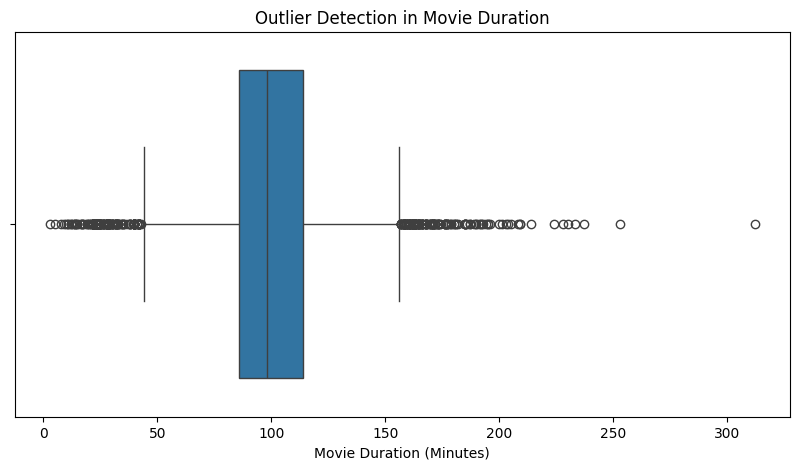

In [31]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=movie_data['movie_duration'])

plt.title('Outlier Detection in Movie Duration')

plt.xlabel('Movie Duration (Minutes)')

plt.show()

TV show season outliers

In [30]:
tv_data = df_clean[df_clean['type'] == 'TV Show']

Q1 = tv_data['seasons'].quantile(0.25)

Q3 = tv_data['seasons'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

tv_outliers = tv_data[
    (tv_data['seasons'] < lower_limit) |
    (tv_data['seasons'] > upper_limit)
]

print("Number of TV show outliers:", len(tv_outliers))

Number of TV show outliers: 231


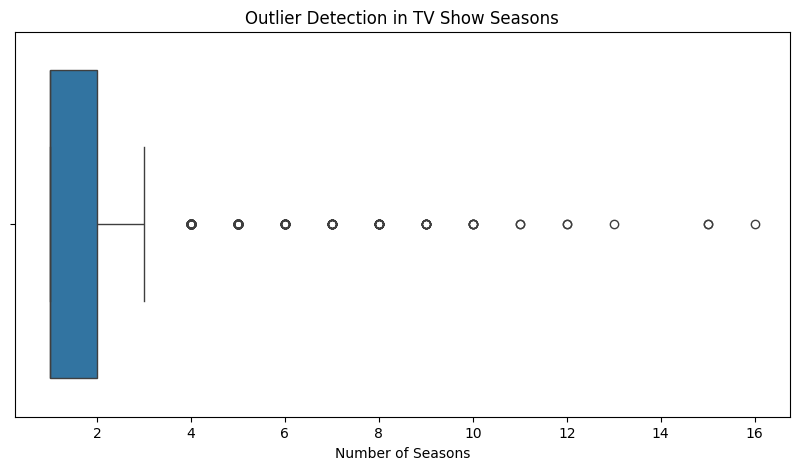

In [32]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=tv_data['seasons'])

plt.title('Outlier Detection in TV Show Seasons')

plt.xlabel('Number of Seasons')

plt.show()

**Feature Engineering**

content addition year

In [33]:
 df_clean['date_added_year'] = df_clean['date_added'].dt.year

addition month

In [34]:
df_clean['date_added_month'] = df_clean['date_added'].dt.month_name()


release decade column

In [35]:
df_clean['release_decade'] = (
    df_clean['release_year'] // 10
) * 10

CHECK GARUM

In [38]:
df_clean[['date_added', 'date_added_year', 'date_added_month', 'release_decade']].head(4)

,date_added,date_added_year,date_added_month,release_decade
0,2020-08-14,2020,August,2020
1,2017-12-15,2017,December,2000
2,2019-01-05,2019,January,2010
3,2016-03-01,2016,March,2010


Aba yo cleaned dataset save garum

In [39]:
df_clean.to_csv('Netflix_Cleaned.csv', index=False)

**EDA**

**BUSINESS QUESTIONS**

- Which content type dominates Netflix?

- What is the percentage difference?

- Does Netflix have a greater variety of movies or TV shows?

**Movies vs TV Shows** IN count plot herum

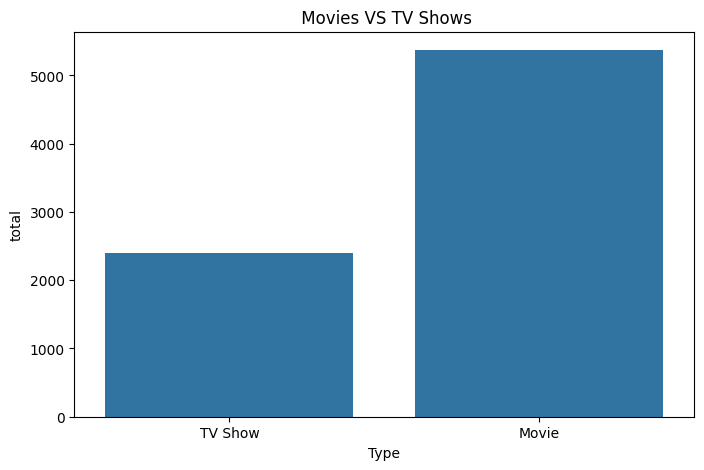

In [41]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='type'
)

plt.title(' Movies VS TV Shows')

plt.xlabel('Type')

plt.ylabel('total')

plt.show()

**Content Growth Over Time**


**Business Questions**

- During which year did Netflix add the most content?

- Was content addition increasing or decreasing?

- Did Netflix experience a sudden increase or decline?

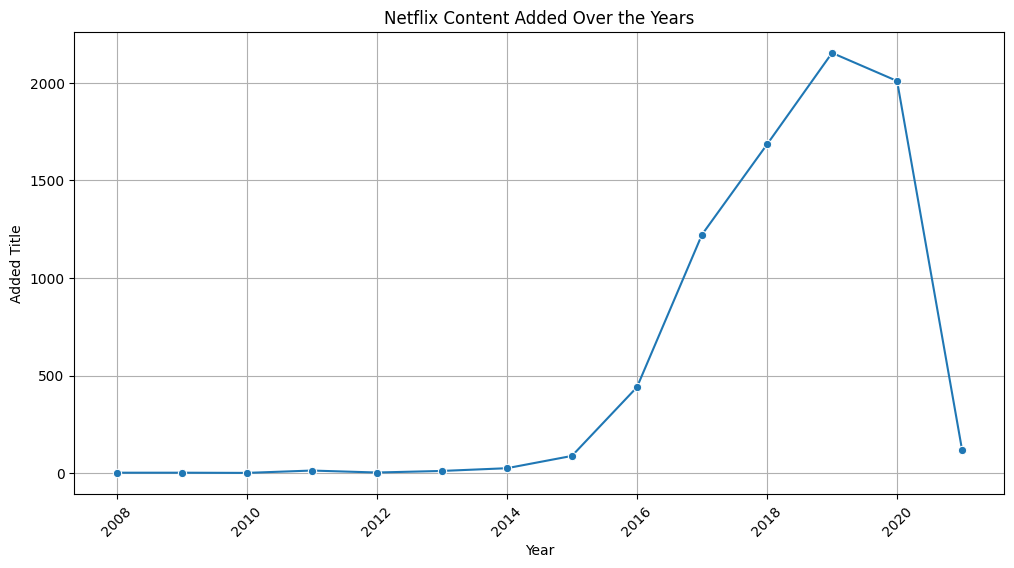

In [42]:
yearly_content = df_clean['date_added_year'].value_counts().sort_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=yearly_content.index,
    y=yearly_content.values,
    marker='o'
)

plt.title('Netflix Content Added Over the Years')

plt.xlabel('Year')

plt.ylabel('Added Title')

plt.xticks(rotation=45)

plt.grid(True)

plt.show()

In [43]:
print("Year with highest content additions:",yearly_content.idxmax())
print("Number of titles added:",yearly_content.max())

Year with highest content additions: 2019
Number of titles added: 2153


**Country Analysis**



**Business questions**

- Which country contributes the most content?

- Which countries dominate Netflix's content library?

- How significant is international content?

In [45]:
country_data = df_clean[
    df_clean['country'] != 'Not Given'].copy()

country_data['country'] = country_data['country'].str.split(',')

country_data = country_data.explode('country')

country_data['country'] = country_data['country'].str.strip()

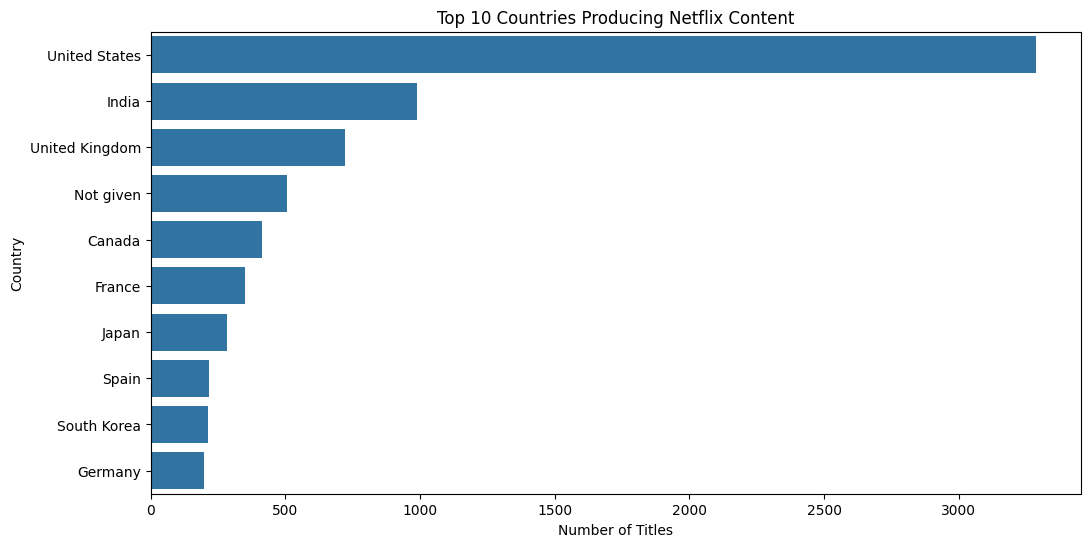

In [46]:
top_countries = country_data['country'].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title('Top 10 Countries Producing Netflix Content')

plt.xlabel('Number of Titles')

plt.ylabel('Country')

plt.show()

**Genre Analysis**


**Business questions**
1. Which genre dominates Netflix?
2. What are the most common entertainment categories?
3. Does Netflix have a stronger presence in international content, dramas or movies?

In [48]:
genre_data = df_clean.copy()

genre_data['genres'] = genre_data['genres'].str.split(',')

genre_data = genre_data.explode('genres')

genre_data['genres'] = genre_data['genres'].str.strip()

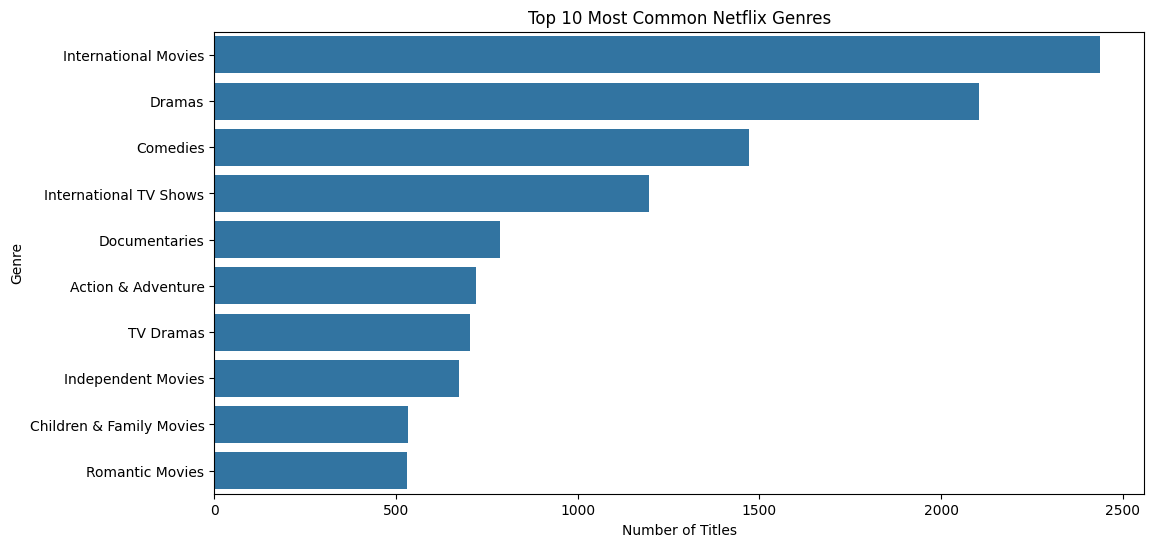

In [49]:
top_genres = genre_data['genres'].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title('Top 10 Most Common Netflix Genres')

plt.xlabel('Number of Titles')

plt.ylabel('Genre')

plt.show()